# 4-1. 시점 반영

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 불러오기
df = pd.read_csv('/content/마스터_B_동월.csv')

print(df.shape)
print(df.columns.tolist())
print(df['기준연월'].min(), df['기준연월'].max())

df.head()

In [ ]:
# 월별 제주 전체 외국인 방문 합계
monthly_visit = (
    df.groupby('기준연월', as_index=False)['방문']
      .sum()
      .sort_values('기준연월')
)

# 연도와 월 생성
monthly_visit['연도'] = monthly_visit['기준연월'] // 100
monthly_visit['월'] = monthly_visit['기준연월'] % 100

monthly_visit

In [ ]:
!apt-get -qq install fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 캐시 갱신
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

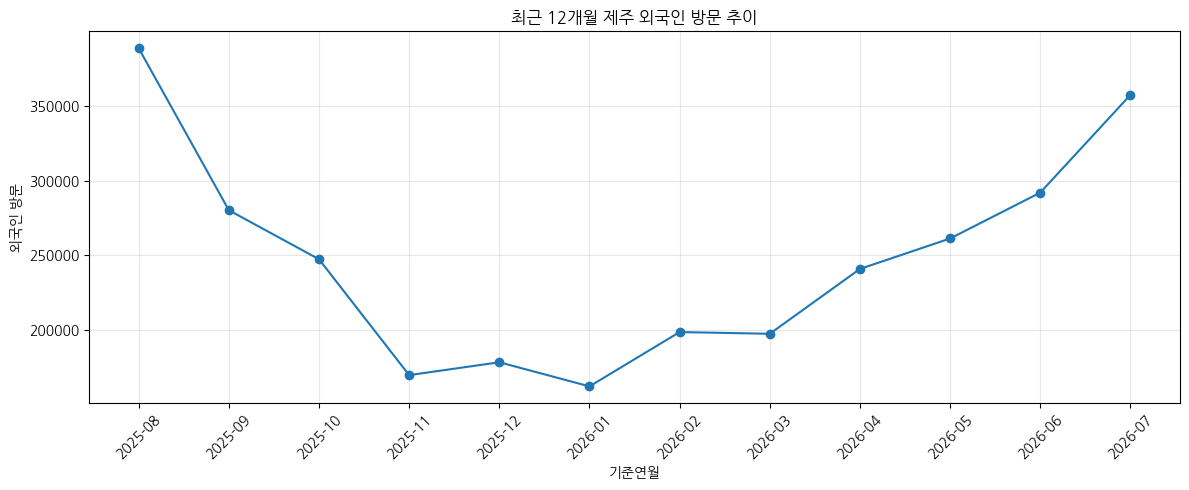

In [ ]:
# 기존 분석과 동일한 최근 12개월만 선택
recent = monthly_visit[
    (monthly_visit['기준연월'] >= 202508) &
    (monthly_visit['기준연월'] <= 202607)
].copy()

# 보기 편한 월 라벨
recent['월표시'] = recent['기준연월'].astype(str).str[:4] + '-' + \
                   recent['기준연월'].astype(str).str[4:]

# 표 확인
print(recent[['월표시', '방문']].to_string(index=False))

# 그래프
plt.figure(figsize=(12, 5))
plt.plot(recent['월표시'], recent['방문'], marker='o')

plt.title('최근 12개월 제주 외국인 방문 추이')
plt.xlabel('기준연월')
plt.ylabel('외국인 방문')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 최근 12개월 원자료
recent_df = df[
    (df['기준연월'] >= 202508) &
    (df['기준연월'] <= 202607)
].copy()

# 월별 제주 전체 합계
monthly_all = (
    recent_df
    .groupby('기준연월', as_index=False)
    [['방문', '건수_음식소매', '금액_음식소매']]
    .sum()
    .sort_values('기준연월')
)

monthly_all['월표시'] = (
    monthly_all['기준연월'].astype(str).str[:4]
    + '-'
    + monthly_all['기준연월'].astype(str).str[4:]
)

monthly_all

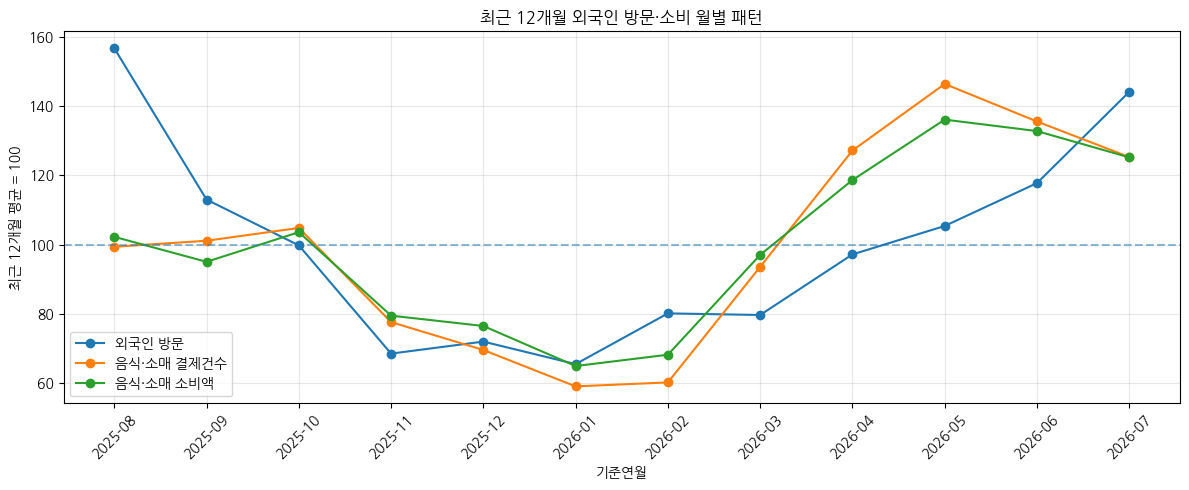

In [ ]:
# 최근 12개월 평균 = 100으로 변환
for col in ['방문', '건수_음식소매', '금액_음식소매']:
    monthly_all[col + '_지수'] = (
        monthly_all[col] / monthly_all[col].mean() * 100
    )

plt.figure(figsize=(12, 5))

plt.plot(monthly_all['월표시'], monthly_all['방문_지수'],
         marker='o', label='외국인 방문')

plt.plot(monthly_all['월표시'], monthly_all['건수_음식소매_지수'],
         marker='o', label='음식·소매 결제건수')

plt.plot(monthly_all['월표시'], monthly_all['금액_음식소매_지수'],
         marker='o', label='음식·소매 소비액')

plt.axhline(100, linestyle='--', alpha=0.5)

plt.title('최근 12개월 외국인 방문·소비 월별 패턴')
plt.xlabel('기준연월')
plt.ylabel('최근 12개월 평균 = 100')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
# 비교할 시기 정의
periods = {
    '가을': [202509, 202510],
    '겨울': [202512, 202601],
    '여름': [202606, 202607]
}

season_list = []

for season, months in periods.items():

    temp = df[df['기준연월'].isin(months)].copy()

    # 동별 2개월 합계
    temp = (
        temp.groupby(
            ['행정동코드', '행정동명'],
            as_index=False
        )[['방문', '금액_음식소매', '건수_음식소매']]
        .sum()
    )

    temp['시기'] = season

    season_list.append(temp)

season_df = pd.concat(season_list, ignore_index=True)

# 확인
season_df.groupby('시기').agg(
    동수=('행정동명', 'nunique'),
    방문=('방문', 'sum'),
    소비액=('금액_음식소매', 'sum'),
    결제건수=('건수_음식소매', 'sum')
)

In [ ]:
demand_results = []

for season in ['가을', '겨울', '여름']:

    temp = season_df[season_df['시기'] == season].copy()

    # 해당 시기의 하위 25% 기준
    visit_q1 = temp['방문'].quantile(0.25)
    tx_q1 = temp['건수_음식소매'].quantile(0.25)

    # 방문 OR 결제건수 중 하나라도 Q1 이상이면 통과
    temp['수요필터_통과'] = (
        (temp['방문'] >= visit_q1) |
        (temp['건수_음식소매'] >= tx_q1)
    )

    temp['방문_Q1'] = visit_q1
    temp['결제건수_Q1'] = tx_q1

    demand_results.append(temp)

season_demand = pd.concat(demand_results, ignore_index=True)

# 시기별 결과 요약
summary = (
    season_demand
    .groupby('시기')
    .agg(
        방문_Q1=('방문_Q1', 'first'),
        결제건수_Q1=('결제건수_Q1', 'first'),
        통과동수=('수요필터_통과', 'sum')
    )
)

summary['제외동수'] = 43 - summary['통과동수']

summary

In [ ]:
for season in ['가을', '겨울', '여름']:
    excluded = season_demand[
        (season_demand['시기'] == season) &
        (~season_demand['수요필터_통과'])
    ][['행정동명', '방문', '건수_음식소매']]

    print(f'\n[{season}] 제외 {len(excluded)}개 동')
    print(excluded.to_string(index=False))

In [ ]:
gap_results = []

for season in ['가을', '겨울', '여름']:

    # 해당 계절 + 수요필터 통과 동만
    temp = season_demand[
        (season_demand['시기'] == season) &
        (season_demand['수요필터_통과'])
    ].copy()

    # 방문당 소비
    temp['방문당소비'] = (
        temp['금액_음식소매'] / temp['방문']
    )

    # 해당 계절의 중앙값
    gap_median = temp['방문당소비'].median()

    # 중앙값 미만 = 할인 배치 대상
    temp['할인배치대상'] = (
        temp['방문당소비'] < gap_median
    )

    temp['소비갭_기준'] = gap_median

    gap_results.append(temp)

season_gap = pd.concat(gap_results, ignore_index=True)

# 결과 요약
gap_summary = (
    season_gap
    .groupby('시기')
    .agg(
        수요필터통과동=('행정동명', 'count'),
        방문당소비_중앙값=('소비갭_기준', 'first'),
        할인대상동=('할인배치대상', 'sum')
    )
)

gap_summary

In [ ]:
# 계절별 할인 대상 여부를 한 표로 변환
target_compare = (
    season_gap
    .pivot(
        index='행정동명',
        columns='시기',
        values='할인배치대상'
    )
    .reset_index()
)

# 수요필터에서 탈락한 동은 False로 처리
target_compare[['가을', '겨울', '여름']] = (
    target_compare[['가을', '겨울', '여름']]
    .fillna(False)
    .astype(bool)
)

# 보기 쉽게 O / X
for col in ['가을', '겨울', '여름']:
    target_compare[col] = target_compare[col].map({
        True: 'O',
        False: 'X'
    })

target_compare

In [ ]:
# 동별 계절 상태 만들기
status_list = []

for season in ['가을', '겨울', '여름']:

    demand_temp = season_demand[
        season_demand['시기'] == season
    ][['행정동명', '수요필터_통과']].copy()

    gap_temp = season_gap[
        season_gap['시기'] == season
    ][['행정동명', '할인배치대상']].copy()

    temp = demand_temp.merge(
        gap_temp,
        on='행정동명',
        how='left'
    )

    def classify(row):
        if not row['수요필터_통과']:
            return '수요 부족'
        elif row['할인배치대상']:
            return '할인 대상'
        else:
            return '대상 아님'

    temp[season] = temp.apply(classify, axis=1)

    status_list.append(
        temp[['행정동명', season]].set_index('행정동명')
    )

# 계절별 상태 결합
season_status = pd.concat(status_list, axis=1).reset_index()

season_status

In [ ]:
# 할인 대상 횟수 계산
season_check = season_status.copy()

season_check['할인대상_횟수'] = (
    (season_check['가을'] == '할인 대상').astype(int) +
    (season_check['겨울'] == '할인 대상').astype(int) +
    (season_check['여름'] == '할인 대상').astype(int)
)

# 유형 분류
def season_type(row):
    n = row['할인대상_횟수']

    if n == 3:
        return '안정적 할인 대상'
    elif n == 0:
        return '비대상'
    else:
        return '계절 민감'

season_check['계절유형'] = season_check.apply(season_type, axis=1)

# 유형별 개수
print(season_check['계절유형'].value_counts())

# 계절 민감 지역만 확인
season_check[
    season_check['계절유형'] == '계절 민감'
][
    ['행정동명', '가을', '겨울', '여름',
     '할인대상_횟수', '계절유형']
]

In [ ]:
import numpy as np

cause_results = []

for season in ['가을', '겨울', '여름']:

    # 해당 계절의 수요필터 통과 동
    temp = season_gap[
        season_gap['시기'] == season
    ].copy()

    # 전환과 객단가 계산
    temp['전환'] = (
        temp['건수_음식소매'] / temp['방문']
    )

    temp['객단가'] = (
        temp['금액_음식소매'] / temp['건수_음식소매']
    )

    # 수요필터 통과 동 전체의 기하평균
    전환_gmean = np.exp(np.log(temp['전환']).mean())
    객단가_gmean = np.exp(np.log(temp['객단가']).mean())

    # 기준 대비 얼마나 부족한지 로그로 계산
    temp['전환부족'] = np.log(전환_gmean / temp['전환'])
    temp['객단가부족'] = np.log(객단가_gmean / temp['객단가'])

    # 할인 대상만 원인 분류
    temp['원인'] = np.where(
        temp['전환부족'] > temp['객단가부족'],
        '전환형',
        '객단가형'
    )

    # 할인 대상이 아닌 곳은 원인 없음
    temp.loc[~temp['할인배치대상'], '원인'] = '대상 아님'

    cause_results.append(temp)

season_cause = pd.concat(cause_results, ignore_index=True)

# 계절별 할인 대상의 원인 유형 개수 확인
season_cause[
    season_cause['할인배치대상']
].groupby(['시기', '원인']).size().unstack(fill_value=0)

In [ ]:
# 계절별 원인을 동별 한 표로 만들기
cause_compare = (
    season_cause
    .pivot(
        index='행정동명',
        columns='시기',
        values='원인'
    )
    .reset_index()
)

cause_compare[['가을', '겨울', '여름']] = (
    cause_compare[['가을', '겨울', '여름']]
    .fillna('수요 부족')
)

cause_compare

In [ ]:
# 전환형/객단가형이 계절에 따라 바뀐 동 찾기

def cause_changed(row):
    # 실제 할인 대상인 계절의 원인만 추출
    causes = [
        row[s] for s in ['가을', '겨울', '여름']
        if row[s] in ['전환형', '객단가형']
    ]

    # 전환형과 객단가형이 둘 다 나타나면 원인 변화
    return len(set(causes)) > 1


cause_compare['할인유형_변화'] = cause_compare.apply(
    cause_changed,
    axis=1
)

changed_cause = cause_compare[
    cause_compare['할인유형_변화']
][['행정동명', '가을', '겨울', '여름']]

print("할인 유형이 계절에 따라 바뀐 동:",
      len(changed_cause), "개")

changed_cause

In [ ]:
# 여름 기준 다음 회차 할인 배치안
next_plan = season_cause[
    (season_cause['시기'] == '여름') &
    (season_cause['할인배치대상'])
].copy()

# 할인 방식 붙이기
next_plan['할인설계'] = next_plan['원인'].map({
    '전환형': '문턱 낮은 정률 할인',
    '객단가형': '최소 결제금액 조건 할인'
})

# 소비갭 크기도 계산
# 해당 여름 기준선 대비 얼마나 소비가 부족한지
next_plan['소비갭(로그)'] = np.log(
    next_plan['소비갭_기준'] / next_plan['방문당소비']
)

# 필요한 컬럼만
next_plan = next_plan[[
    '행정동명',
    '방문',
    '금액_음식소매',
    '건수_음식소매',
    '방문당소비',
    '소비갭(로그)',
    '전환',
    '객단가',
    '원인',
    '할인설계'
]].copy()

# 소비갭이 큰 순서로 정렬
next_plan = next_plan.sort_values(
    '소비갭(로그)',
    ascending=False
).reset_index(drop=True)

# 보기 좋게 반올림
next_plan['방문당소비'] = next_plan['방문당소비'].round(0)
next_plan['소비갭(로그)'] = next_plan['소비갭(로그)'].round(3)
next_plan['전환'] = next_plan['전환'].round(3)
next_plan['객단가'] = next_plan['객단가'].round(0)

print("다음 여름 회차 할인 배치 대상:", len(next_plan), "개 동")
print(next_plan['원인'].value_counts())

next_plan

In [ ]:
# 기존 최근 12개월 배치안
annual_plan = {
    '동홍동': '전환형',
    '화북동': '전환형',
    '오라동': '전환형',
    '도두동': '전환형',
    '예래동': '전환형',
    '이도2동': '전환형',
    '삼도1동': '전환형',
    '한경면': '전환형',
    '대정읍': '전환형',
    '남원읍': '전환형',
    '중문동': '전환형',
    '일도2동': '전환형',
    '용담1동': '전환형',

    '송산동': '객단가형',
    '대천동': '객단가형',
    '이도1동': '객단가형',
    '한림읍': '객단가형',
    '정방동': '객단가형'
}

annual_df = pd.DataFrame(
    annual_plan.items(),
    columns=['행정동명', '연중안']
)

# 여름안
summer_df = next_plan[
    ['행정동명', '원인']
].rename(
    columns={'원인': '여름안'}
)

# 두 배치안 합치기
compare_final = annual_df.merge(
    summer_df,
    on='행정동명',
    how='outer'
)

compare_final['연중안'] = compare_final['연중안'].fillna('대상 아님')
compare_final['여름안'] = compare_final['여름안'].fillna('대상 아님')

# 변화 유형
def compare_plan(row):

    if row['연중안'] == row['여름안']:
        return '유지'

    elif row['연중안'] == '대상 아님':
        return '신규 진입'

    elif row['여름안'] == '대상 아님':
        return '대상 이탈'

    else:
        return '할인 방식 변경'

compare_final['변화'] = compare_final.apply(
    compare_plan,
    axis=1
)

# 변화가 있는 지역 먼저 보기
compare_final = compare_final.sort_values(
    '변화'
)

print(compare_final['변화'].value_counts())

compare_final

In [ ]:
# 1. 계절별 대상 상태
season_check.to_csv(
    '/content/4-1_계절별_할인대상_비교.csv',
    index=False,
    encoding='utf-8-sig'
)

# 2. 계절별 할인 원인/방식
cause_compare.to_csv(
    '/content/4-1_계절별_할인방식_비교.csv',
    index=False,
    encoding='utf-8-sig'
)

# 3. 다음 여름 회차 배치안
next_plan.to_csv(
    '/content/4-1_다음여름_배치안.csv',
    index=False,
    encoding='utf-8-sig'
)

# 4. 최근 12개월안 vs 다음 여름안
compare_final.to_csv(
    '/content/4-1_연중_vs_다음여름.csv',
    index=False,
    encoding='utf-8-sig'
)

print("저장 완료!")

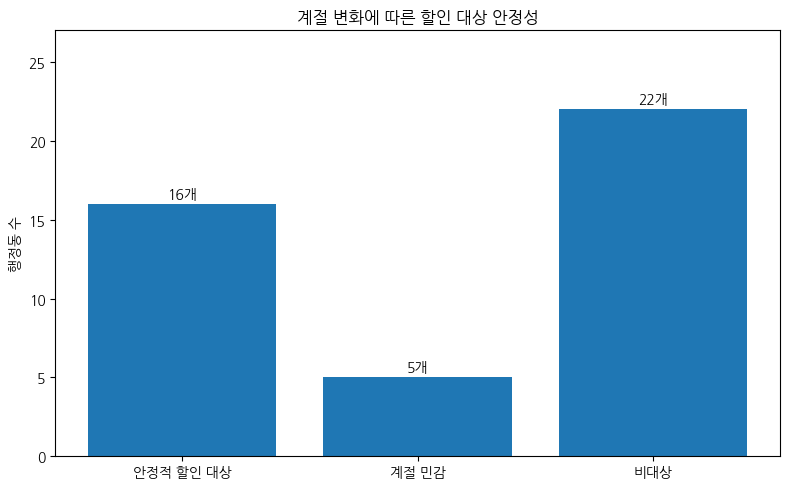

In [ ]:
# 계절 유형 개수
plot_data = (
    season_check['계절유형']
    .value_counts()
    .reindex(['안정적 할인 대상', '계절 민감', '비대상'])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    plot_data.index,
    plot_data.values
)

plt.title('계절 변화에 따른 할인 대상 안정성')
plt.ylabel('행정동 수')
plt.ylim(0, max(plot_data.values) + 5)

# 막대 위 숫자
for bar, value in zip(bars, plot_data.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.4,
        f'{value}개',
        ha='center'
    )

plt.tight_layout()
plt.show()

# 4-3. 과거 대조

In [ ]:
# 현재 만들어져 있는 데이터프레임 확인
for name in ['df', 'season_status', 'cause_compare', 'next_plan']:
    if name in globals():
        print(name, globals()[name].shape)
        print(globals()[name].columns.tolist())
        print()

In [ ]:
import numpy as np
import pandas as pd

# 과거 프로모션 시행지역
past_places = ['일도1동', '중앙동', '애월읍']

# 최근 12개월
recent = df[
    (df['기준연월'] >= 202508) &
    (df['기준연월'] <= 202607)
].copy()

# 동별 12개월 합계
annual = (
    recent.groupby('행정동명', as_index=False)
    .agg({
        '방문': 'sum',
        '금액_음식소매': 'sum',
        '건수_음식소매': 'sum'
    })
)

# -------------------------
# 1. 수요 필터 재현
# -------------------------
visit_q1 = annual['방문'].quantile(0.25)
count_q1 = annual['건수_음식소매'].quantile(0.25)

annual['수요필터'] = np.where(
    (annual['방문'] <= visit_q1) &
    (annual['건수_음식소매'] <= count_q1),
    '수요 부족',
    '통과'
)

# -------------------------
# 2. 소비갭 판단
# -------------------------
annual['방문당소비'] = (
    annual['금액_음식소매'] / annual['방문']
)

passed = annual[annual['수요필터'] == '통과'].copy()

spend_median = passed['방문당소비'].median()

annual['현재진단'] = np.where(
    annual['수요필터'] == '수요 부족',
    '수요 부족',
    np.where(
        annual['방문당소비'] < spend_median,
        '할인 대상',
        '대상 아님'
    )
)

# -------------------------
# 3. 과거 시행지역만 추출
# -------------------------
past_compare = annual[
    annual['행정동명'].isin(past_places)
][[
    '행정동명',
    '방문',
    '금액_음식소매',
    '건수_음식소매',
    '방문당소비',
    '수요필터',
    '현재진단'
]].copy()

past_compare['방문당소비'] = past_compare['방문당소비'].round(0)

print("방문 Q1:", round(visit_q1))
print("결제건수 Q1:", round(count_q1))
print("방문당소비 중앙값:", round(spend_median))

past_compare

In [ ]:
# =========================================
# 4-3 STEP 3
# 2024년 당시 기준으로 프레임워크 재실행
# =========================================

# 2024년 데이터
past_2024 = df[
    (df['기준연월'] >= 202401) &
    (df['기준연월'] <= 202412)
].copy()

# 동별 합계
annual_2024 = (
    past_2024.groupby('행정동명', as_index=False)
    .agg({
        '방문': 'sum',
        '금액_음식소매': 'sum',
        '건수_음식소매': 'sum'
    })
)

# ① 수요 필터 기준 재계산
visit_q1_2024 = annual_2024['방문'].quantile(0.25)
count_q1_2024 = annual_2024['건수_음식소매'].quantile(0.25)

annual_2024['수요필터'] = np.where(
    (annual_2024['방문'] <= visit_q1_2024) &
    (annual_2024['건수_음식소매'] <= count_q1_2024),
    '수요 부족',
    '통과'
)

# ② 방문당 소비
annual_2024['방문당소비'] = (
    annual_2024['금액_음식소매'] /
    annual_2024['방문']
)

# 수요 필터 통과 지역만 기준 계산
passed_2024 = annual_2024[
    annual_2024['수요필터'] == '통과'
].copy()

spend_median_2024 = passed_2024['방문당소비'].median()

# ③ 할인 대상 판단
annual_2024['2024진단'] = np.where(
    annual_2024['수요필터'] == '수요 부족',
    '수요 부족',
    np.where(
        annual_2024['방문당소비'] < spend_median_2024,
        '할인 대상',
        '대상 아님'
    )
)

# ④ 과거 실제 시행지역만 확인
past_2024_compare = annual_2024[
    annual_2024['행정동명'].isin(
        ['일도1동', '중앙동', '애월읍']
    )
][[
    '행정동명',
    '방문',
    '금액_음식소매',
    '건수_음식소매',
    '방문당소비',
    '수요필터',
    '2024진단'
]].copy()

past_2024_compare['방문당소비'] = (
    past_2024_compare['방문당소비'].round(0)
)

print("=== 2024년 기준 ===")
print("방문 Q1:", round(visit_q1_2024))
print("결제건수 Q1:", round(count_q1_2024))
print("방문당소비 중앙값:", round(spend_median_2024))
print()
print("수요필터 통과:", (annual_2024['수요필터'] == '통과').sum(), "개 동")
print("할인 대상:", (annual_2024['2024진단'] == '할인 대상').sum(), "개 동")

past_2024_compare

In [ ]:
def diagnose_period(start_month, end_month, target_places):

    # 해당 기간 데이터
    temp = df[
        (df['기준연월'] >= start_month) &
        (df['기준연월'] <= end_month)
    ].copy()

    # 43개 동 집계
    area = (
        temp.groupby('행정동명', as_index=False)
        .agg({
            '방문': 'sum',
            '금액_음식소매': 'sum',
            '건수_음식소매': 'sum'
        })
    )

    # ① 수요 필터
    visit_q1 = area['방문'].quantile(0.25)
    count_q1 = area['건수_음식소매'].quantile(0.25)

    area['수요필터'] = np.where(
        (area['방문'] <= visit_q1) &
        (area['건수_음식소매'] <= count_q1),
        '수요 부족',
        '통과'
    )

    # ② 방문당 소비
    area['방문당소비'] = (
        area['금액_음식소매'] / area['방문']
    )

    # ③ 해당 시점 소비갭 기준
    passed = area[area['수요필터'] == '통과']
    median_spend = passed['방문당소비'].median()

    # ④ 진단
    area['진단'] = np.where(
        area['수요필터'] == '수요 부족',
        '수요 부족',
        np.where(
            area['방문당소비'] < median_spend,
            '할인 대상',
            '대상 아님'
        )
    )

    result = area[
        area['행정동명'].isin(target_places)
    ][[
        '행정동명',
        '방문',
        '금액_음식소매',
        '건수_음식소매',
        '방문당소비',
        '수요필터',
        '진단'
    ]].copy()

    result['방문당소비'] = result['방문당소비'].round(0)

    print(f'기간: {start_month} ~ {end_month}')
    print('방문 Q1:', round(visit_q1))
    print('결제건수 Q1:', round(count_q1))
    print('방문당소비 중앙값:', round(median_spend))
    print('할인 대상:', (area["진단"] == "할인 대상").sum(), '개 동')
    print()

    return result


# 1·2회차: 전통시장 프로모션 시행 직전
market_before = diagnose_period(
    202401, 202403,
    ['일도1동', '중앙동']
)

print("=== 전통시장 프로모션 직전 ===")
display(market_before)


# 3회차: 애월 카페거리 프로모션 시행 직전
aewol_before = diagnose_period(
    202405, 202407,
    ['애월읍']
)

print("=== 애월 카페거리 프로모션 직전 ===")
display(aewol_before)

In [ ]:
# =========================================
# 4-3 STEP 5
# 과거 시점에 우리 프레임워크가 선택했을 지역
# =========================================

def get_past_targets(start_month, end_month):

    temp = df[
        (df['기준연월'] >= start_month) &
        (df['기준연월'] <= end_month)
    ].copy()

    # 동별 집계
    area = (
        temp.groupby('행정동명', as_index=False)
        .agg({
            '방문': 'sum',
            '금액_음식소매': 'sum',
            '건수_음식소매': 'sum'
        })
    )

    # ① 수요 필터
    visit_q1 = area['방문'].quantile(0.25)
    count_q1 = area['건수_음식소매'].quantile(0.25)

    area['수요필터'] = np.where(
        (area['방문'] <= visit_q1) &
        (area['건수_음식소매'] <= count_q1),
        '수요 부족',
        '통과'
    )

    # ② 방문당 소비
    area['방문당소비'] = (
        area['금액_음식소매'] / area['방문']
    )

    # 수요 필터 통과 지역 기준 중앙값
    passed = area[
        area['수요필터'] == '통과'
    ].copy()

    median_spend = passed['방문당소비'].median()

    # ③ 할인 대상
    passed['진단'] = np.where(
        passed['방문당소비'] < median_spend,
        '할인 대상',
        '대상 아님'
    )

    # ④ 소비갭(log)
    passed['소비갭(로그)'] = np.where(
        passed['진단'] == '할인 대상',
        np.log(median_spend / passed['방문당소비']),
        np.nan
    )

    # 할인 대상만 + 소비갭 큰 순서
    targets = (
        passed[passed['진단'] == '할인 대상']
        .sort_values('소비갭(로그)', ascending=False)
        .reset_index(drop=True)
    )

    targets['순위'] = range(1, len(targets) + 1)

    return targets[[
        '순위',
        '행정동명',
        '방문',
        '금액_음식소매',
        '건수_음식소매',
        '방문당소비',
        '소비갭(로그)'
    ]]


# -----------------------------------------
# 1·2회차 전통시장 시행 직전
# 2024.01 ~ 03
# -----------------------------------------
market_targets = get_past_targets(202401, 202403)

print("=== 전통시장 시행 직전: 우리 프레임워크 할인 대상 ===")
display(market_targets.head(10))


# -----------------------------------------
# 3회차 애월 카페거리 시행 직전
# 2024.05 ~ 07
# -----------------------------------------
aewol_targets = get_past_targets(202405, 202407)

print("=== 애월 카페거리 시행 직전: 우리 프레임워크 할인 대상 ===")
display(aewol_targets.head(10))

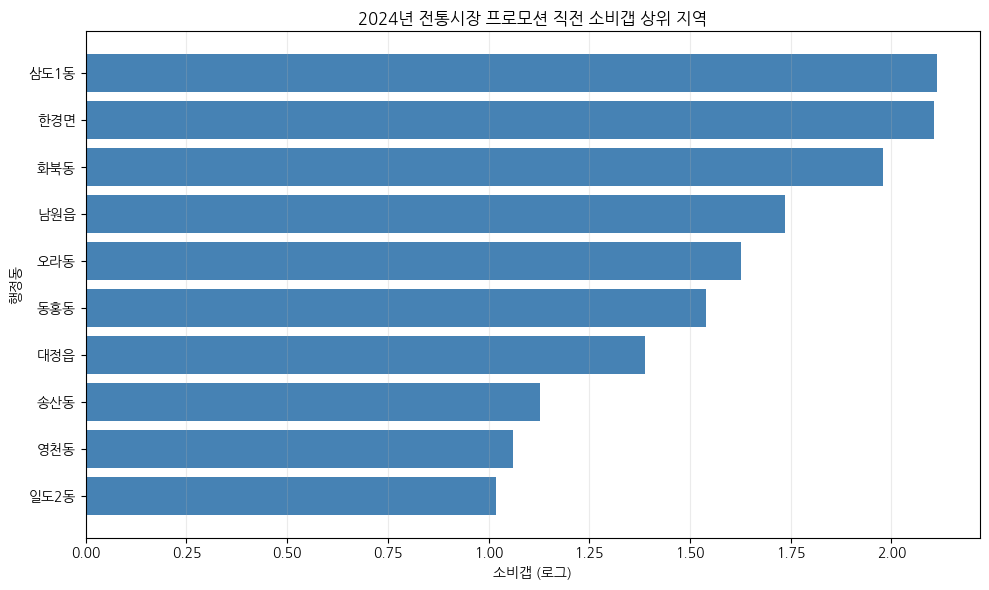

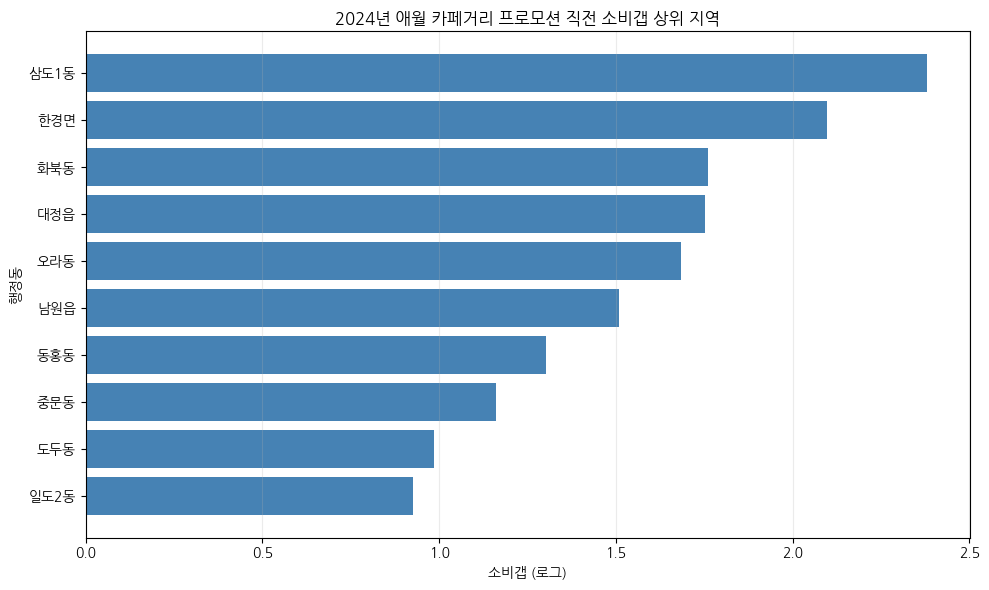

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 한글 폰트
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False


def plot_past_comparison(targets, actual_places, title):

    plot_df = targets.head(10).copy()

    # 실제 시행지역을 표시하기 위한 색
    colors = [
        'tomato' if dong in actual_places else 'steelblue'
        for dong in plot_df['행정동명']
    ]

    plt.figure(figsize=(10, 6))

    plt.barh(
        plot_df['행정동명'][::-1],
        plot_df['소비갭(로그)'][::-1],
        color=colors[::-1]
    )

    plt.xlabel('소비갭 (로그)')
    plt.ylabel('행정동')
    plt.title(title)

    plt.grid(axis='x', alpha=0.25)

    plt.tight_layout()
    plt.show()


# 전통시장 시행 직전
plot_past_comparison(
    market_targets,
    ['일도1동', '중앙동'],
    '2024년 전통시장 프로모션 직전 소비갭 상위 지역'
)

# 애월 카페거리 시행 직전
plot_past_comparison(
    aewol_targets,
    ['애월읍'],
    '2024년 애월 카페거리 프로모션 직전 소비갭 상위 지역'
)

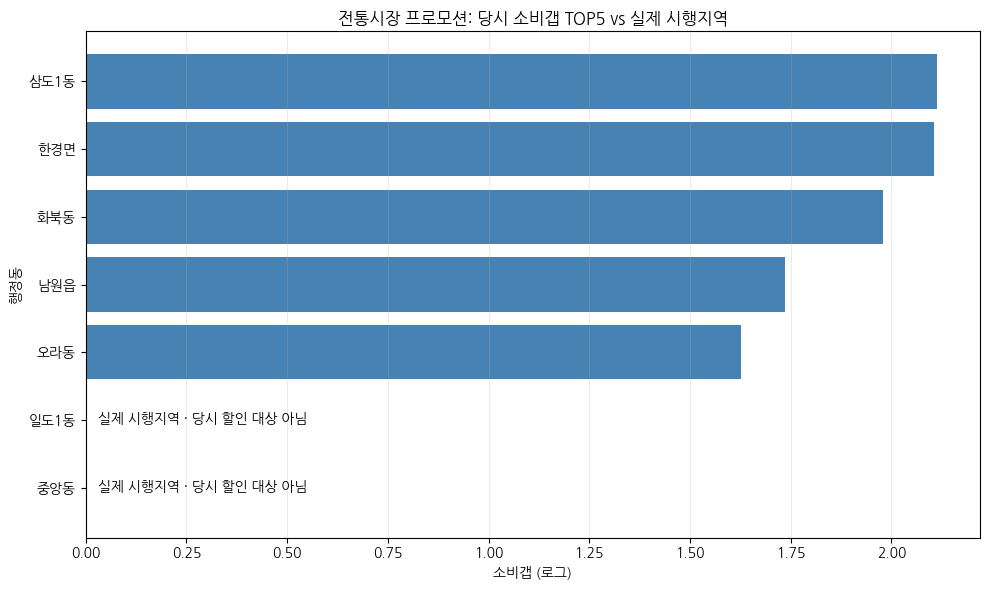

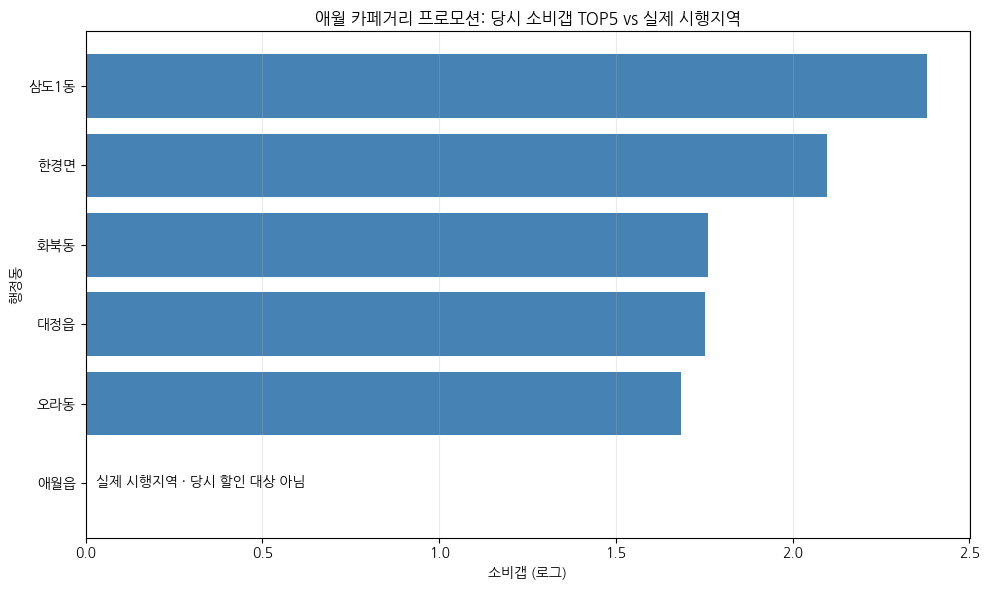

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False


def plot_top5_vs_actual(targets, actual_df, actual_places, title):

    # 우리 프레임워크 소비갭 TOP5
    top5 = targets.head(5)[
        ['행정동명', '소비갭(로그)']
    ].copy()

    top5['구분'] = '소비갭 TOP5'

    # 실제 시행지역
    actual = actual_df[
        actual_df['행정동명'].isin(actual_places)
    ][['행정동명', '방문당소비']].copy()

    # 당시 기준선 가져오기
    # 소비갭 = ln(중앙값 / 방문당소비)
    # 실제 시행지는 대상 아님 → 소비갭을 0으로 표시
    actual['소비갭(로그)'] = 0
    actual['구분'] = '실제 시행지역'

    # 합치기
    plot_df = pd.concat([
        top5[['행정동명', '소비갭(로그)', '구분']],
        actual[['행정동명', '소비갭(로그)', '구분']]
    ], ignore_index=True)

    # 색 지정
    colors = [
        'steelblue' if x == '소비갭 TOP5'
        else 'tomato'
        for x in plot_df['구분']
    ]

    plt.figure(figsize=(10, 6))

    bars = plt.barh(
        plot_df['행정동명'][::-1],
        plot_df['소비갭(로그)'][::-1],
        color=colors[::-1]
    )

    plt.xlabel('소비갭 (로그)')
    plt.ylabel('행정동')
    plt.title(title)

    # 실제 시행지역 표시
    for bar, category in zip(bars, plot_df['구분'][::-1]):
        if category == '실제 시행지역':
            plt.text(
                0.03,
                bar.get_y() + bar.get_height()/2,
                '실제 시행지역 · 당시 할인 대상 아님',
                va='center',
                fontsize=10
            )

    plt.grid(axis='x', alpha=0.25)
    plt.tight_layout()
    plt.show()


# ① 전통시장
plot_top5_vs_actual(
    market_targets,
    market_before,
    ['일도1동', '중앙동'],
    '전통시장 프로모션: 당시 소비갭 TOP5 vs 실제 시행지역'
)


# ② 애월 카페거리
plot_top5_vs_actual(
    aewol_targets,
    aewol_before,
    ['애월읍'],
    '애월 카페거리 프로모션: 당시 소비갭 TOP5 vs 실제 시행지역'
)